In [0]:
#import statement
from pyspark.sql import SparkSession
import pandas as pd
from pyspark.ml.feature import OneHotEncoder
from pyspark.ml.feature import StringIndexer
from pyspark.ml.feature import VectorAssembler
from pyspark.ml import Pipeline

In [0]:
df = spark.read.csv("/FileStore/tables/bank.csv", header=True, inferSchema=True)
df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- deposit: string (nullable = true)



In [0]:
# DF operations
df.head(5)
df.select('age', 'balance', 'deposit').show(5)
df.groupBy("age").count().sort("count",ascending =True).show()
df.describe().show()
df.describe('balance').show()
df.filter(df.age >40).count()
df.groupby('marital').agg({'balance':'mean'}).show()

+---+-------+-------+
|age|balance|deposit|
+---+-------+-------+
| 59|   2343|    yes|
| 56|     45|    yes|
| 41|   1270|    yes|
| 55|   2476|    yes|
| 54|    184|    yes|
+---+-------+-------+
only showing top 5 rows

+---+-----+
|age|count|
+---+-----+
| 95|    1|
| 89|    1|
| 93|    2|
| 92|    2|
| 88|    2|
| 90|    2|
| 87|    4|
| 86|    5|
| 84|    5|
| 85|    5|
| 83|    7|
| 18|    8|
| 81|    9|
| 82|   10|
| 79|   10|
| 19|   13|
| 80|   17|
| 75|   18|
| 74|   18|
| 78|   19|
+---+-----+
only showing top 20 rows

+-------+------------------+-------+--------+---------+-------+------------------+-------+-----+--------+------------------+-----+------------------+------------------+------------------+------------------+--------+-------+
|summary|               age|    job| marital|education|default|           balance|housing| loan| contact|               day|month|          duration|          campaign|             pdays|          previous|poutcome|deposit|
+-------+------

In [0]:
row_count = df.filter(df.age > 40).count()
print(f"Number of rows: {row_count}")

Number of rows: 4967


In [0]:
#panda dataframe
pd.DataFrame(df.take(5), columns=df.columns).transpose()

,0,1,2,3,4
age,59,56,41,55,54
job,admin.,admin.,technician,services,admin.
marital,married,married,married,married,married
education,secondary,secondary,secondary,secondary,tertiary
default,no,no,no,no,no
balance,2343,45,1270,2476,184
housing,yes,no,yes,yes,no
loan,no,no,no,no,no
contact,unknown,unknown,unknown,unknown,unknown
day,5,5,5,5,5


In [0]:
numeric_features =[t[0] for t in df.dtypes if t[1] == 'int']
df.select(numeric_features).describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
age,11162,41.231947679627304,11.913369192215518,18,95
balance,11162,1528.5385235620856,3225.413325946149,-6847,81204
day,11162,15.658036194230425,8.420739541006462,1,31
duration,11162,371.99381831213043,347.12838571630687,2,3881
campaign,11162,2.508421429851281,2.7220771816614824,1,63
pdays,11162,51.33040673714388,108.75828197197717,-1,854
previous,11162,0.8325568894463358,2.292007218670508,0,58


In [0]:
categoricalColumns =['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']
stages =[]
for categoricalCol in categoricalColumns:
    stringIndexer = StringIndexer(inputCol =categoricalCol, outputCol = categoricalCol + 'Index')
    encoder =OneHotEncoder(inputCols =[stringIndexer.getOutputCol()], outputCols =[categoricalCol + "classVec"])
    stages += [stringIndexer, encoder]
label_stringIdx =StringIndexer(inputCol = 'deposit', outputCol= 'label')
stages += [label_stringIdx]
numericCols =['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
assemblerInputs = [c + "classVec" for c in categoricalColumns] + numericCols
assembler = VectorAssembler(inputCols =assemblerInputs, outputCol ="features")
stages += [assembler]

In [0]:
pipeline =Pipeline(stages =stages)
pipelineModel = pipeline.fit(df)
df= pipelineModel.transform(df)
df.printSchema

Out[11]: <bound method DataFrame.printSchema of DataFrame[age: int, job: string, marital: string, education: string, default: string, balance: int, housing: string, loan: string, contact: string, day: int, month: string, duration: int, campaign: int, pdays: int, previous: int, poutcome: string, deposit: string, jobIndex: double, jobclassVec: vector, maritalIndex: double, maritalclassVec: vector, educationIndex: double, educationclassVec: vector, defaultIndex: double, defaultclassVec: vector, housingIndex: double, housingclassVec: vector, loanIndex: double, loanclassVec: vector, contactIndex: double, contactclassVec: vector, poutcomeIndex: double, poutcomeclassVec: vector, label: double, features: vector]>

In [0]:
pd.DataFrame(df.take(5), columns =df.columns).transpose()

,0,1,2,3,4
age,59,56,41,55,54
job,admin.,admin.,technician,services,admin.
marital,married,married,married,married,married
education,secondary,secondary,secondary,secondary,tertiary
default,no,no,no,no,no
balance,2343,45,1270,2476,184
housing,yes,no,yes,yes,no
loan,no,no,no,no,no
contact,unknown,unknown,unknown,unknown,unknown
day,5,5,5,5,5


In [0]:
train, test =df.randomSplit([0.8, 0.2], seed =99999)
from pyspark.ml.clustering import KMeans
import numpy as np
cost = np.zeros(10)
for k in range(2,10):
    kmeans = KMeans().setK(k).setSeed(1)
    model = kmeans.fit(train)
    cost[k] = model.summary.trainingCost

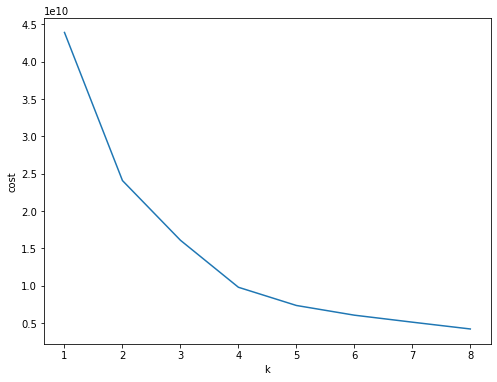

In [0]:
import matplotlib.mlab as mlab
import matplotlib.pyplot as plt 
import seaborn as sbs
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots(1,1, figsize =(8,6))
ax.plot(range(1,9), cost[2:10])
ax.set_xlabel('k')
ax.set_ylabel('cost')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

In [0]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
kmeans = KMeans().setK(8).setSeed(999)
model = kmeans.fit(train)

In [0]:
evaluator = ClusteringEvaluator()
predictions = model.transform(train)
silhouette = evaluator.evaluate(predictions)
print("Training Dataset Performance = " + str(silhouette))

Training Dataset Performance = 0.6105315427081663


In [0]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
kmeans = KMeans().setK(2).setSeed(999)
model = kmeans.fit(train)

In [0]:
evaluator = ClusteringEvaluator()
predictions = model.transform(train)
silhouette = evaluator.evaluate(predictions)
print("Training Dataset Performance = " + str(silhouette))

Training Dataset Performance = 0.9294982858743319


In [0]:
centers = model.clusterCenters()
print("Cluster Centers: ")
for center in centers:
    print(center)

Cluster Centers: 
[2.25965489e-01 1.75372696e-01 1.61990844e-01 1.21727902e-01
 8.32257307e-02 7.19568024e-02 3.61544782e-02 3.20460148e-02
 3.14590914e-02 2.95809367e-02 2.39464726e-02 5.67907031e-01
 3.14003991e-01 4.98180538e-01 3.24216457e-01 1.32762061e-01
 9.84857378e-01 5.21187933e-01 8.64890245e-01 7.20976640e-01
 2.09296866e-01 7.44101420e-01 1.11515436e-01 9.61380444e-02
 4.11090504e+01 1.01845944e+03 3.71641507e+02 2.50616270e+00
 5.15993661e+01 8.37657002e-01]
[3.21256039e-01 1.03864734e-01 1.93236715e-01 7.00483092e-02
 4.10628019e-02 1.06280193e-01 4.34782609e-02 3.38164251e-02
 3.62318841e-02 2.65700483e-02 1.69082126e-02 6.01449275e-01
 3.06763285e-01 3.42995169e-01 4.71014493e-01 1.42512077e-01
 1.00000000e+00 6.57004831e-01 9.56521739e-01 7.58454106e-01
 1.35265700e-01 6.90821256e-01 1.25603865e-01 1.25603865e-01
 4.44396135e+01 1.19120942e+04 3.93468599e+02 2.59661836e+00
 5.65338164e+01 1.06521739e+00]


In [0]:
kmeans = KMeans().setK(8).setSeed(999)
model = kmeans.fit(test)

In [0]:
evaluator = ClusteringEvaluator()
predections =model.transform(test)
silhouette = evaluator.evaluate(predictions)
print("testing Dataset Performance = " + str(silhouette))

testing Dataset Performance = 0.9294982858743319
